# 20 — Khả thi triển khai RF trên ESP32

> **Phạm vi:** proof of concept phân loại motion phenotype dựa trên proxy label — KHÔNG phải bộ phân loại an toàn hàng hải đã xác thực. Proxy label không phải ground truth; không có nhãn hazard đã xác minh hay quyết định human review nào được dùng.

Feature set desktop = 23 angle feature (quyết định thiết kế của M2). Notebook so sánh với contract/firmware hiện có, ước lượng tài nguyên và đo lệch miền do chuỗi lọc.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/labeling/proxy_rules.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/labeling/proxy_rules.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 100, "font.size": 9})
PROXY = REPO_ROOT / "ml/data/labels/proxy_v1"
summary = json.loads((REPO_ROOT / "ml/reports/ml/proxy_dataset_summary.json").read_text())
measurements = pd.read_parquet(PROXY / "measurements.parquet")
labels = pd.read_parquet(PROXY / "proxy_labels_oof.parquet")
data = measurements.merge(labels, on="window_id", validate="one_to_one")
TARGETS = ["RELATIVE_HIGH_ROLL", "PERSISTENT_OFFSET", "AMPLITUDE_GROWTH"]
import sklearn
exe = Path(sys.executable)
print("Interpreter:", exe.relative_to(REPO_ROOT) if REPO_ROOT in exe.parents else exe.name, "| scikit-learn", sklearn.__version__)
print("Rule version:", summary["rule_version"], "| cửa sổ:", len(data), "| đủ 23 feature:", int(data.angle23_complete.sum()))
esp = json.loads((REPO_ROOT / "ml/reports/ml/esp32_feasibility.json").read_text())
contract = json.loads((REPO_ROOT / "ml/docs/feature_contract_23_v0.1.json").read_text())

Interpreter: .venv/bin/python | scikit-learn 1.9.1
Rule version: proxy_rules_v1.0.0 | cửa sổ: 3425 | đủ 23 feature: 2864


## Feature set desktop và đề xuất contract `svmg-angle23` v0.1.0

In [2]:
display(pd.DataFrame(contract["features"]))
print({k: contract[k] for k in ("sampling_hz", "endpoint_convention", "update_stride_seconds", "status")})

,index,name,spec_id,signal,window_seconds,unit,definition,embedded_strategy
0,0,roll_rms_60,0,roll,60,deg,"sqrt(mean(x^2)) trên (t-60,t]",O(1) tổng bình phương trượt
1,1,roll_std_60,1,roll,60,deg,độ lệch chuẩn quần thể (mẫu số n),O(1) moment trượt ổn định
2,2,roll_mean_60,2,roll,60,deg,mean(x),O(1) tổng trượt
3,3,roll_peak_to_peak_60,3,roll,60,deg,max(x)-min(x),O(1) khấu hao bằng deque đơn điệu
4,4,roll_abs_p95_60,4,roll,60,deg,phân vị Type-7 0.95 của |x|,sắp xếp 600 phần tử/lần cập nhật
5,5,roll_abs_max_60,5,roll,60,deg,max(|x|),O(1) khấu hao bằng deque
6,6,roll_iqr_60,6,roll,60,deg,Q0.75-Q0.25 Type-7,sắp xếp 600 phần tử
7,7,roll_diff_rms_60,7,roll,60,deg/sample @10 Hz,RMS sai phân bậc 1 giữa mẫu kề đúng chu kỳ 0.1 s,O(1); PHỤ THUỘC tần số lấy mẫu
8,8,roll_mean_180,11,roll,180,deg,mean(x),O(1) tổng trượt
9,9,roll_median_180,12,roll,180,deg,Q0.50 Type-7,sắp xếp 1800 phần tử


{'sampling_hz': 10.0, 'endpoint_convention': '(t-W, t]', 'update_stride_seconds': 10.0, 'status': 'PROPOSAL_PENDING_M1_REVIEW'}


## So sánh với contract và chuỗi firmware hiện có

In [3]:
legacy = ["rms_roll", "p95_roll", "rms_pitch", "p95_pitch", "max_abs_roll", "energy_roll", "zero_crossing_rate", "mean_roll", "mean_pitch",
          "std_roll", "trend_rms_slope", "heel_duration_s", "data_quality_pct", "sensor_ok"]
from ml.labeling.human_review_workflow import ANGLE_FEATURES
print("Feature trùng tên giữa contract 14 trường và 23 feature:", sorted(set(legacy) & set(ANGLE_FEATURES)) or "không có")
display(pd.Series(esp["current_firmware_chain"]).to_frame("firmware hiện tại"))

Feature trùng tên giữa contract 14 trường và 23 feature: không có


,firmware hiện tại
input_hz,20
complementary_filter_tau_s,7.5
lowpass,"Butterworth bậc 2, 0.5 Hz"
output_hz,2
short_window_samples,120
long_window_samples,360
update_every_samples,10
source,"core/include/svmg_filter.h, core/src/filter.c,..."


Không có tập con nào của 23 feature trùng định nghĩa với vector hiện tại của firmware (khác tần số 2 Hz vs 10 Hz, khác lọc, khác công thức), nên thí nghiệm "tập con tương thích" **không khả thi** mà không có thay đổi từ M1. Thay vào đó, notebook đo trực tiếp ảnh hưởng của chuỗi lọc hiện tại.

## Ước lượng RAM/flash/latency (chưa đo trên thiết bị)

In [4]:
display(pd.Series(esp["memory"]["feature_ram_bytes"]).to_frame("byte"))
display(pd.DataFrame(esp["memory"]["models"]).T)
display(pd.DataFrame(esp["compact_models"]).T)

,byte
roll_ring_180s_float32,7200
pitch_ring_60s_float32,2400
validity_bits,300
quantile_scratch_1800_float32,7200
outputs_and_flags,115
total,17215


,estimated_c_array_bytes,total_nodes,n_estimators,max_depth,mean_comparisons_per_inference,max_comparisons_per_inference,latency_estimate_us_at_240MHz_20_cycles_per_comparison
RELATIVE_HIGH_ROLL,8400.0,1150.0,200.0,5.0,316.756614,330.0,27.5


,f1,params,median_estimated_c_array_bytes
RELATIVE_HIGH_ROLL,1.0,"{'n_estimators': 25, 'max_depth': 6, 'min_samp...",1380.0


## Thí nghiệm 1: std 60 s sau chuỗi lọc firmware (0.5 Hz, 2 Hz)

In [5]:
from ml.train.esp32_feasibility import firmware_chain_emulation
cal = json.loads((PROXY / "calibrations.json").read_text())["final_all_hohai_groups"]
emu = firmware_chain_emulation(REPO_ROOT, measurements, cal)
display(pd.Series({k: v for k, v in emu.items() if not isinstance(v, dict)}).to_frame("giá trị"))
display(pd.DataFrame({"gốc 10 Hz": emu["proxy_decisions_original"], "sau chuỗi firmware": emu["proxy_decisions_emulated"]}).fillna(0).astype(int))

,giá trị
windows,1512
std_ratio_median,0.665955
std_ratio_p05,0.631151
std_ratio_p95,0.728149
samples_per_60s_window_2hz,120
decisions_changed,299
original_pos_now_not_pos,148
nyquist_2hz_output_hz,1.0
approximation,Lọc 0.5 Hz trên chuỗi 10 Hz rồi lấy mỗi mẫu th...


,gốc 10 Hz,sau chuỗi firmware
NEG,1209,1502
POS,152,4
ABSTAIN,151,6


## Thí nghiệm 2: trích lại đủ 23 feature trên tín hiệu lọc 0.5 Hz (giữ 10 Hz) và dự đoán bằng mô hình cuối

Cô lập ảnh hưởng của bộ lọc (không giảm mẫu) bằng chính extractor của pipeline.

In [6]:
import yaml
from scipy import signal
from ml.features.extractor import extract_segment
from ml.train.predict import load_model, predict_frame
settings = yaml.safe_load((REPO_ROOT / "ml/features/config.yaml").read_text())["features"]
model, card = load_model(REPO_ROOT / "ml/data/models/rf_poc_v1/relative_high_roll_model_card.json", REPO_ROOT)
sos = signal.butter(2, 0.5, fs=10.0, output="sos")
orig_rows, filt_rows = [], []
for session in sorted(measurements[measurements.dataset_source == "hohai"].session_id.unique()):
    seg = REPO_ROOT / "ml/data/processed/hohai" / session / "segment_000"
    frame = pd.read_parquet(seg / "timeseries.parquet"); prov = json.loads((seg / "provenance.json").read_text())
    for col in ("roll_deg", "pitch_deg"):
        x = frame[col].to_numpy(float); frame[col] = signal.sosfilt(sos, x, zi=signal.sosfilt_zi(sos) * x[0])[0]
    values, meta, _ = extract_segment(frame, prov, settings, "hohai")
    ok = meta.validity_json.map(lambda s: all(json.loads(s)[f]["status"] == "VALID" for f in ANGLE_FEATURES))
    filt_rows.append(values[ok.to_numpy()].assign(dataset_source="hohai"))
filtered = pd.concat(filt_rows, ignore_index=True)
original = measurements[(measurements.dataset_source == "hohai") & measurements.angle23_complete]
p_orig = predict_frame(model, card, original); p_filt = predict_frame(model, card, filtered)
display(pd.DataFrame({"gốc 10 Hz": p_orig.proxy_prediction.value_counts(), "lọc 0.5 Hz": p_filt.proxy_prediction.value_counts()}).fillna(0).astype(int))
display(p_filt.abstain_reason.value_counts())

,gốc 10 Hz,lọc 0.5 Hz
proxy_prediction,,
ABSTAIN,0,505
NEG,1324,1003
POS,188,4


abstain_reason
                                  1007
FEATURE_OUTSIDE_TRAINING_RANGE     505
Name: count, dtype: int64

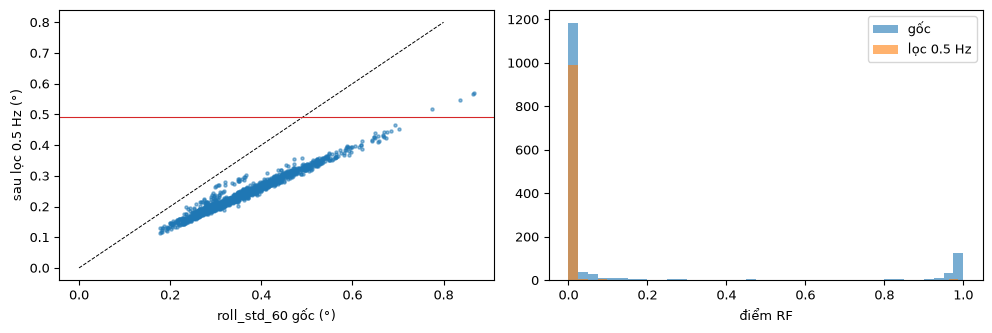

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
merged = original[["window_id", "roll_std_60"]].merge(filtered[["window_id", "roll_std_60"]], on="window_id", suffixes=("_goc", "_loc"))
ax[0].scatter(merged.roll_std_60_goc, merged.roll_std_60_loc, s=5, alpha=.5); ax[0].plot([0, .8], [0, .8], "k--", lw=.7)
ax[0].axhline(cal["domains"]["hohai"]["RELATIVE_HIGH_ROLL"]["positive_threshold"], color="tab:red", lw=.8)
ax[0].set_xlabel("roll_std_60 gốc (°)"); ax[0].set_ylabel("sau lọc 0.5 Hz (°)")
ax[1].hist(p_orig.proxy_score.dropna(), bins=40, alpha=.6, label="gốc"); ax[1].hist(p_filt.proxy_score.dropna(), bins=40, alpha=.6, label="lọc 0.5 Hz")
ax[1].set_xlabel("điểm RF"); ax[1].legend(); plt.tight_layout(); plt.show()

## Thí nghiệm 3: Roll từ gia tốc kế so với Roll của dataset (Southampton Run 14)

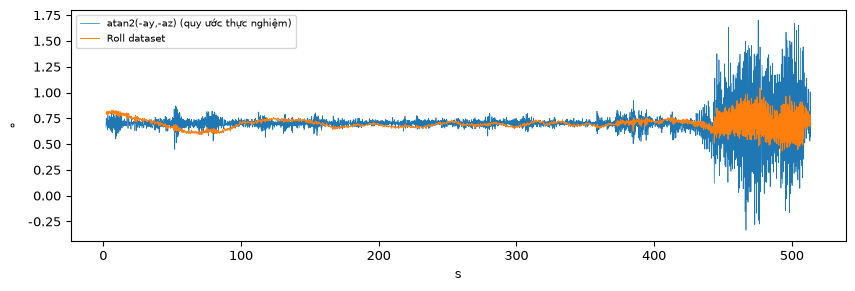

,giá trị
samples,5117
convention,"atan2(-ay, -az) (chọn để khớp dấu; chưa xác minh)"
dataset_roll_mean_deg,0.697909
accel_roll_mean_deg,0.702618
dataset_roll_std_deg,0.055423
accel_roll_std_deg,0.142466
pearson_r,0.551227
rms_difference_deg,0.121184


In [8]:
ts = pd.read_parquet(REPO_ROOT / "ml/data/processed/southampton/southampton_run_14/segment_000/timeseries.parquet").dropna(subset=["accel_y_m_s2"])
acc_roll = np.degrees(np.arctan2(-ts.accel_y_m_s2, -ts.accel_z_m_s2))
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(ts.time_seconds, acc_roll, lw=.5, label="atan2(-ay,-az) (quy ước thực nghiệm)"); ax.plot(ts.time_seconds, ts.roll_deg, lw=.7, label="Roll dataset")
ax.set_xlabel("s"); ax.set_ylabel("°"); ax.legend(fontsize=7); plt.show()
display(pd.Series(esp["southampton_accel_roll_check"]).to_frame("giá trị"))

## Giới hạn triển khai

- Chưa đo RAM/flash/latency trên ESP32; chưa có cài đặt C và golden-vector parity cho 23 feature.
- Chuỗi firmware hiện tại (2 Hz, lọc 0.5 Hz, bộ lọc bù MPU6050) cho feature khác hệ thống so với dữ liệu huấn luyện; hai thí nghiệm trên đo được mức lệch.
- Model học trên Hohai model-scale (chu kỳ ~1.8 s); tàu full-scale có chu kỳ dài hơn nhiều.
- Không tạo `ml/export/model.h` vì firmware sẽ tự include và giả định 4 lớp loại trừ.

## Giải thích kỹ thuật phục vụ vấn đáp cá nhân

Bộ nhớ không phải trở ngại (≈ 17 KB cho bộ đệm feature, vài KB cho cây). Trở ngại là **tín hiệu đầu vào khác miền**: cùng một chuyển động, chuỗi xử lý khác cho feature khác, và model đúng trên PC có thể sai hệ thống trên thiết bị. Vì vậy chưa được gọi là deployable.